# Model evaluation

**Research objective.** Compare saved, matched validation predictions using correct source-taxonomy semantics.

All results are read from local FNEWS artifacts. `SOURCE_TRUE` and `SOURCE_NON_TRUE` are Fakeddit source-taxonomy labels, not independently verified factuality labels. The held-out test partition is not opened by these notebooks except where a prior frozen metric is explicitly quoted.

In [1]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd()
if not (ROOT / "data/research_dataset").exists():
    ROOT = Path("/Users/aka_ank/Desktop/FNEWS")
DATA = ROOT / "data/research_dataset"
REPORTS = ROOT / "reports"
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.titlesize": 13, "axes.labelsize": 11})

def paired(split):
    frame = pd.read_parquet(DATA / "manifests" / f"{split}_manifest.parquet")
    return frame.loc[(frame.source_dataset == "Fakeddit") & (frame.download_status == "verified_reused_or_processed")].copy().reset_index(drop=True)

def canonical_source_labels(raw):
    """Fakeddit raw 1=true; return 0=SOURCE_TRUE, 1=SOURCE_NON_TRUE."""
    return 1 - np.asarray(raw, dtype=int)

def source_names(values):
    return np.where(np.asarray(values) == 0, "SOURCE_TRUE", "SOURCE_NON_TRUE")

def show_frame(frame, rows=10):
    display(frame.head(rows))


## Evaluation protocol

Macro-F1 weights both classes equally, which is valuable when source-taxonomy classes differ in frequency. Accuracy alone can hide asymmetric errors. All comparisons below use the same 933 validation IDs and are not external factuality scores.

In [2]:
from sklearn.metrics import confusion_matrix,precision_recall_fscore_support,accuracy_score,f1_score
paths={'LinearSVC':REPORTS/'experiments/research_dataset_baselines/tfidf_svm/validation_predictions.parquet','Frozen pretrained text':REPORTS/'experiments/research_dataset_baselines/pretrained_text_frozen/validation_predictions.parquet','ResNet-18':REPORTS/'experiments/research_dataset_baselines/resnet18_frozen/validation_predictions.parquet','Weighted fusion':REPORTS/'weighted_late_fusion_v1/validation_predictions.parquet','CLIP gated (archived)':REPORTS/'multimodal_fusion/clip_fusion_v1/gated/validation_predictions.parquet'}
rows=[]
for name,path in paths.items():
 d=pd.read_parquet(path);y=canonical_source_labels(d.label);p=canonical_source_labels(d.prediction);cm=confusion_matrix(y,p,labels=[0,1]);rows.append({'model':name,'ids':d.sample_id.nunique(),'accuracy':accuracy_score(y,p),'macro_f1':f1_score(y,p,average='macro'),'true_recall':cm[0,0]/cm[0].sum(),'non_true_recall':cm[1,1]/cm[1].sum(),'balanced_accuracy':np.mean([cm[0,0]/cm[0].sum(),cm[1,1]/cm[1].sum()]),'matrix':cm.tolist()})
comparison=pd.DataFrame(rows);display(comparison.sort_values('macro_f1',ascending=False))

,model,ids,accuracy,macro_f1,true_recall,non_true_recall,balanced_accuracy,matrix
4,CLIP gated (archived),933,0.874598,0.870700,0.867374,0.879496,0.873435,"[[327, 50], [67, 489]]"
3,Weighted fusion,933,0.764202,0.759459,0.771883,0.758993,0.765438,"[[291, 86], [134, 422]]"
0,LinearSVC,933,0.720257,0.717136,0.761273,0.692446,0.726860,"[[287, 90], [171, 385]]"
1,Frozen pretrained text,933,0.691318,0.688974,0.748011,0.652878,0.700444,"[[282, 95], [193, 363]]"
2,ResNet-18,933,0.693462,0.686088,0.668435,0.710432,0.689433,"[[252, 125], [161, 395]]"


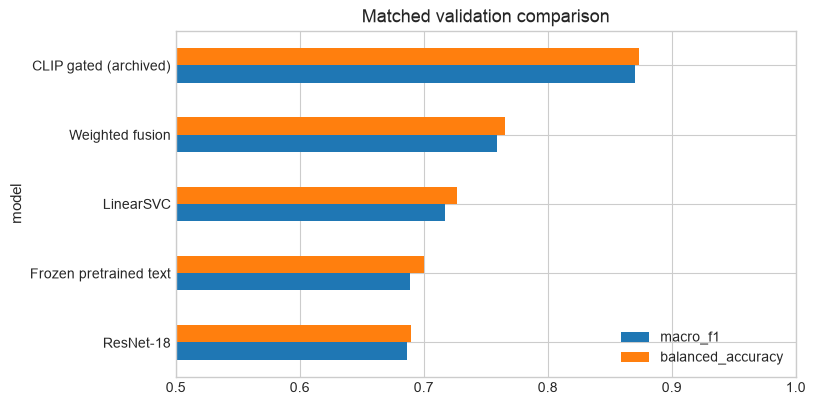

In [3]:
fig,ax=plt.subplots();comparison.set_index('model')[['macro_f1','balanced_accuracy']].sort_values('macro_f1').plot.barh(ax=ax,title='Matched validation comparison');ax.set_xlim(.5,1);plt.show()

## Frozen test record

A previously recorded single test result exists for the archived gated model (86.91% accuracy, 86.45% macro-F1 on 947 pairs). It is historical, was not reread here, and was not used for selection.